# Statistics 7: Hypothesis tests

*Learning path: probability and statistics, part 7 of 8.* [Index](README.md) · Previous: [Estimation and confidence](06-estimation-and-confidence.ipynb) · Next: [Regression and correlation](08-regression-and-correlation.ipynb)

In 1710 John Arbuthnot, physician to Queen Anne, looked at the christening records of London for the 82 years from
1629 to 1710. In every single year more boys than girls had been christened. If boys and girls were equally likely,
each year would be a coin toss, and 82 heads in a row would have probability $(1/2)^{82}$, about 2 in $10^{25}$.
Arbuthnot concluded that the excess of boys was no accident. His argument was the first **significance test**: assume
the boring explanation, compute how surprising the data would be under it, and reject it if they would be very
surprising.

**Who this is for.** You have done lessons 1 to 6.

**What you will be able to do afterwards:**

1. set up a null hypothesis and compute a p-value, exactly and by simulation;
2. test a mean with Student's t-test, for one sample, paired data and two samples (`ttest`);
3. test counts with the chi-square test, for goodness of fit and for independence in a table (`chi2test`);
4. explain what a p-value is not, and why testing many hypotheses produces false discoveries.

Plan about an hour and a quarter.

## 1. Null hypotheses and p-values

Arbuthnot's calculation:

In [1]:
simplify((1/2)^82)
eval((1/2)^82)

1/4835703278458516698824704

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

2.0679515313825692e-25

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The **null hypothesis** $H_0$ is the boring explanation: here, boys and girls are equally likely. The **p-value** is
the probability, computed under $H_0$, of data at least as extreme as those observed. A small p-value means the data
would be very surprising if $H_0$ were true. By a long convention, $p < 0.05$ is called **statistically
significant**.

A less extreme example: a coin lands heads 60 times in 100 tosses. Is it fair? Under $H_0$ the number of heads is
binomial with $n = 100$, $p = 1/2$. "At least as extreme" means 60 or more heads, or (by symmetry) 40 or fewer:

0.05688793364098079

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

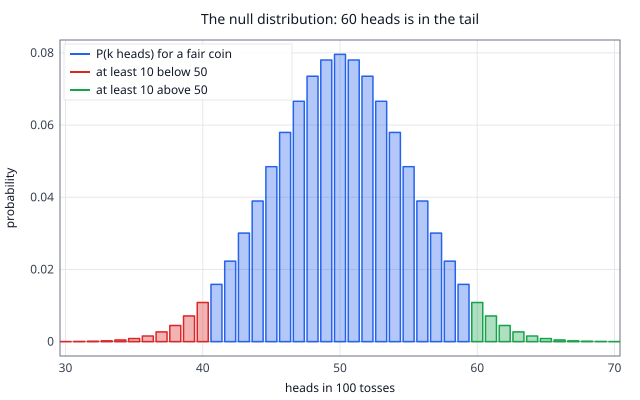

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
eval(2*(1 - binocdf(59, 100, 1/2)))
k = 41:59;
low = 30:40;
high = 60:70;
p = bar(k, binopdf(k, 100, 1/2));
p = show(p, bar(low, binopdf(low, 100, 1/2)));
p = show(p, bar(high, binopdf(high, 100, 1/2)));
p = legend(p, "P(k heads) for a fair coin", "at least 10 below 50", "at least 10 above 50");
labels(title(p, "The null distribution: 60 heads is in the tail"), "heads in 100 tosses", "probability")

The p-value is the total height of the red and green bars: everything at least as far from 50 as the data.

$p = 0.057$: a fair coin does this about one time in 18. That is not below 0.05, so the test does not reject
fairness. Simulation gives the same answer without any formula: toss a fair coin 100 times, 10,000 times over, and
count how often the result is 10 or more away from 50:

In [3]:
seed(3);
x = randbin(100, 1/2, 10000);
simplify(sum(abs(x - 50) >= 10)/10000)

57/1000

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** What is the p-value for 65 heads in 100 tosses?

## 2. The t-test

In 1905 two pharmacologists, Cushny and Peebles, gave two sleeping drugs to the same 10 patients and recorded the
hours of extra sleep. Gosset used their data in his 1908 paper on the t distribution. The extra sleep with each drug:

In [4]:
a = [0.7 -1.6 -0.2 -1.2 -0.1 3.4 3.7 0.8 0.0 2.0];
b = [1.9 0.8 1.1 0.1 -0.1 4.4 5.5 1.6 4.6 3.4];
dif = round(b - a, 1)

[1.2, 2.4, 1.3, 1.3, 0.0, 1.0, 1.8, 0.8, 4.6, 1.4]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

Does drug B give more sleep than drug A? Every patient took both, so look at the differences. Under $H_0$ the mean
difference is 0, and

$$t = \frac{\bar x - 0}{s/\sqrt n}$$

follows Student's t distribution with $n - 1 = 9$ degrees of freedom ([lesson 6](06-estimation-and-confidence.ipynb)).
`ttest(data, mu0)` gives the two-sided p-value, and its note shows the t value:

In [5]:
ttest(dif, 0)
ci(dif)

0.002832890197384197

> One-sample t-test of mean = 0: sample mean 1.580000, t = 4.0621 with 9 degrees of freedom. The answer is the two-sided p-value: the probability of a |t| at least this large if the null hypothesis were true. p < 0.05: significant at the 5% level.

[0.7001142367230214, 2.459885763276979]

> 95% confidence interval for the mean: mean ± t·s/√n = 1.580000 ± 2.262157 × 1.229995/√10, with t = tinv(0.975, 9) = 2.2622 from Student's t distribution with n − 1 = 9 degrees of freedom.

$t = 4.06$ and $p = 0.003$: drug B gives significantly more sleep, about 1.6 hours more, with 95% confidence interval
0.7 to 2.5 hours. A test and an interval tell the same story: the interval leaves out 0 exactly when the 5% test
rejects.

Now ignore the pairing and compare the two lists as if they came from different patients. `ttest(x, y)` does a
two-sample test (Welch's version, which does not assume equal spreads):

In [6]:
ttest(a, b)

0.07939414018735858

> Welch two-sample t-test of equal means: means 0.750000 and 2.330000, t = -1.8608 with 17.78 degrees of freedom. The answer is the two-sided p-value: the probability of a |t| at least this large if the null hypothesis were true. p ≥ 0.05: not significant at the 5% level.

$p = 0.079$: not significant. The patients differ a lot from each other (patient 2 lost sleep on drug A, patient 7
gained 3.7 hours), and that variation swamps the drug effect. Pairing removes it, because each patient is compared with
themselves. **A good design can matter more than a large sample.**

**Try this.** Test whether drug A alone has any effect: `ttest(a, 0)`.

## 3. Chi-square tests for counts

For counts in categories, Karl Pearson (1900) measured the distance between the observed counts $O$ and the counts $E$
expected under $H_0$ by

$$\chi^2 = \sum \frac{(O - E)^2}{E}.$$

Under $H_0$ it follows approximately the **chi-square distribution** with (number of categories $-\,1$) degrees of
freedom, provided the expected counts are not too small (at least 5 is the usual rule). Is a die fair? Roll it 600
times:

In [7]:
seed(1);
r = randint(1, 6, 600);
t = tally(r)
chi2test([120 94 108 102 78 98], [100 100 100 100 100 100])

[  1,  2,   3,   4,  5,  6;
 120, 94, 108, 102, 78, 98]

> tally: the first row lists the distinct values, the second how often each occurs.

0.07753400636438557

> Goodness of fit: χ² = Σ (observed − expected)²/expected = 9.9200 over 6 categories with 5 degrees of freedom. The answer is the p-value P(χ² ≥ 9.9200). p ≥ 0.05: the data are consistent with the hypothesis.

The counts range from 78 to 120, which looks uneven. But $\chi^2 = 9.92$ on 5 degrees of freedom gives $p = 0.078$: a
fair die is this uneven about one time in 13, so there is no evidence against it. (It is fair: the simulation made
it so.) For comparison, the average $\chi^2$ of a fair die is the number of degrees of freedom, 5.

The horse kicks of [lesson 3](03-discrete-distributions.ipynb) are the classic goodness-of-fit example. Combine 2, 3
and 4 deaths into one category so that every expected count is at least 5:

In [8]:
obs = [109 65 26];
expected = [108.67 66.29 25.04];
chi2test(obs, expected)

0.9690342896532741

> Goodness of fit: χ² = Σ (observed − expected)²/expected = 0.0629 over 3 categories with 2 degrees of freedom. The answer is the p-value P(χ² ≥ 0.0629). p ≥ 0.05: the data are consistent with the hypothesis.

The fit is excellent. (Strictly, estimating $\lambda$ from the same data costs one more degree of freedom, leaving 1;
`1 - chi2cdf(0.063, 1)` gives $p = 0.80$, the same conclusion.)

**Try this.** Gregor Mendel crossed pea plants and counted 315 round yellow, 108 round green, 101 wrinkled yellow and
32 wrinkled green seeds. His theory predicts the ratio 9 : 3 : 3 : 1. Test it with
`chi2test([315 108 101 32], 556*[9 3 3 1]/16)`.

## 4. Tables: testing independence

In the Physicians' Health Study (1989), 22,071 American doctors took either aspirin or a placebo every other day. The
heart attacks:

| | heart attack | none |
|---|---|---|
| aspirin | 139 | 10,898 |
| placebo | 239 | 10,795 |

The null hypothesis is that heart attacks are independent of the treatment. The expected count for each cell is
(row total $\times$ column total)/grand total, and `chi2test(table)` does the rest:

In [9]:
chi2test([139 10898; 239 10795])
eval([139/11037, 239/11034])

2.0947195000786678e-7

> Test of independence in a 2×2 table: expected counts (row total × column total)/22071, χ² = 26.9437 with 1 degree of freedom. The answer is the p-value P(χ² ≥ 26.9437). p < 0.05: the data are unlikely under the hypothesis.

[0.01259400199329528, 0.02166032263911546]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The p-value is $2 \times 10^{-7}$. The heart attack rate fell from 2.2% to 1.3%, and with 22,000 participants that is
not chance. The study was stopped early so that the placebo group could benefit.

**Try this.** In a smaller trial with the same rates, 1100 people per group, the counts would be about
`[14 1086; 24 1076]`. Is the difference still significant?

## 5. What a p-value is not

A p-value is the probability of the data (or more extreme) **if $H_0$ is true**. It is **not** the probability that
$H_0$ is true; that confusion is the medical-test error of [lesson 2](02-probability-and-simulation.ipynb) in another
form. Nor does a large p-value prove $H_0$: the unpaired sleep test failed to reject, yet the drugs do differ.

And testing at the 5% level means that **one true null hypothesis in 20 is rejected anyway**. Simulate 1000
experiments, each with a fair coin tossed 100 times, and count how many look significant:

In [10]:
seed(8);
y = randbin(100, 1/2, 1000);
sum(abs(y - 50) >= 10)/1000

63/1000

63 of 1000 perfectly fair coins "fail": the rule "10 or more away from 50" has a false alarm rate of 5.7%, as section 1
showed. A study that tests 20 hypotheses with nothing going on expects one
significant result by chance. Reporting only that one is how false discoveries are made, which is why serious studies
fix their hypotheses in advance and correct for the number of tests (for example, the **Bonferroni** rule: with $m$
tests, use $0.05/m$).

**Try this.** With the Bonferroni rule for 20 tests, how far from 50 must the number of heads be? Use
`eval(2*(1 - binocdf(64, 100, 1/2)))` and `eval(2*(1 - binocdf(65, 100, 1/2)))` to bracket $0.05/20$.

## Summary

* A test assumes a null hypothesis $H_0$ and computes the p-value: the probability, under $H_0$, of data at least as
  extreme. $p < 0.05$ is called significant.
* t-test (`ttest(x, mu0)`, `ttest(x, y)`): means, with $t = (\bar x - \mu_0)/(s/\sqrt n)$. Paired data are tested
  through their differences.
* Chi-square test (`chi2test(observed, expected)`, `chi2test(table)`): $\chi^2 = \sum (O - E)^2/E$ for counts, with
  expected counts of at least 5.
* A p-value is not the probability that $H_0$ is true; many tests produce false positives at the rate of the
  significance level.

Next: [regression and correlation](08-regression-and-correlation.ipynb), the relation between two variables.

## Exercises

1. **Arbuthnot again.** Suppose boys had exceeded girls in 50 of the 82 years. Compute the p-value with `binocdf`.
2. **Cavendish.** Test whether Cavendish's data (lesson 6) are consistent with the modern density 5.513:
   `ttest(d, 5.513)`.
3. **Roulette.** A European roulette wheel has 18 red, 18 black and 1 green pocket. In 370 spins you see 170 red, 190
   black and 10 green. Is the wheel fair?
4. **A two-sample test.** Class A scored `[62 65 68 70 70 71 74 80]` and class B `[45 55 60 70 75 85 90 95]`
   (lesson 1). Do the means differ significantly?
5. **Significance and size.** With a million coin tosses, 50.1% heads gives a p-value of about 0.046. Is the coin
   practically unfair? What does this say about large samples?

## Hints and answers

* **Section 1, Try this.** `eval(2*(1 - binocdf(64, 100, 1/2)))` $\approx 0.0035$.
* **Section 2, Try this.** $p \approx 0.22$: drug A alone has no significant effect.
* **Section 3, Try this.** $p \approx 0.93$: Mendel's counts fit his theory very well (some say too well).
* **Section 4, Try this.** $p \approx 0.10$: with 2200 people the same effect is not significant.
* **Section 5, Try this.** $p = 0.0035$ for 65 or more heads and $0.0018$ for 66 or more; $0.05/20 = 0.0025$ needs 66
  or more (or 34 or fewer): 16 away from 50 instead of 10.
* **Exercise 1.** `eval(2*(1 - binocdf(49, 82, 1/2)))` $\approx 0.06$: not significant.
* **Exercise 2.** $t = -1.59$ and $p \approx 0.12$: consistent with the modern value.
* **Exercise 3.** `chi2test([170 190 10], 370*[18 18 1]/37)` gives $p \approx 0.57$: no evidence against fairness.
* **Exercise 4.** `ttest(a, b)` gives $p \approx 0.79$: the means do not differ significantly.
* **Exercise 5.** No: 0.1% is negligible. Large samples make tiny effects significant; always report the size of the
  effect too.

## Sources

1. J. Arbuthnot, "An argument for divine Providence, taken from the constant regularity observ'd in the births of both
   sexes", *Philosophical Transactions of the Royal Society* 27 (1710) 186–190.
2. A. R. Cushny and A. R. Peebles, "The action of optical isomers II: hyoscines", *Journal of Physiology* 32 (1905)
   501–510; Student, "The probable error of a mean", *Biometrika* 6 (1908) 1–25.
3. K. Pearson, "On the criterion that a given system of deviations from the probable in the case of a correlated
   system of variables is such that it can be reasonably supposed to have arisen from random sampling",
   *Philosophical Magazine* 50 (1900) 157–175.
4. Steering Committee of the Physicians' Health Study Research Group, "Final report on the aspirin component of the
   ongoing Physicians' Health Study", *New England Journal of Medicine* 321 (1989) 129–135.
5. G. Mendel, "Versuche über Pflanzen-Hybriden", *Verhandlungen des naturforschenden Vereines in Brünn* 4 (1866) 3–47.